# EDA — IoT Intrusion Detection Dataset

Análise exploratória do dataset `rahult25/iot-intrusion-detection-dataset` para preparação de dados de Machine Learning.

In [1]:
# 1. Instalação e imports
%pip install -q kagglehub

import os
import glob
import warnings as wr

import kagglehub
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

wr.filterwarnings("ignore")
%matplotlib inline

SEED = 42
TARGET = "label"

sns.set_style("darkgrid")

print("Configuração carregada.")
print("TARGET =", TARGET)


Configuração carregada.
TARGET = label


In [2]:
# 2. Download do dataset
DATASET = "rahult25/iot-intrusion-detection-dataset"

dataset_path = kagglehub.dataset_download(DATASET)

print("Dataset descarregado em:")
print(dataset_path)


100%|██████████| 45.1M/45.1M [00:00<00:00, 165MB/s]

Extracting files...


Dataset descarregado em:
/root/.cache/kagglehub/datasets/rahult25/iot-intrusion-detection-dataset/versions/1


In [3]:
# 3. Procurar automaticamente o CSV correto
csv_files = glob.glob(
    os.path.join(dataset_path, "**", "*.csv"),
    recursive=True
)

print("Ficheiros CSV encontrados:")
for f in csv_files:
    print("-", f)

CSV_PATH = None

for f in csv_files:
    try:
        cols = pd.read_csv(f, nrows=5).columns.tolist()
        if TARGET in cols:
            CSV_PATH = f
            break
    except Exception as e:
        print("Não foi possível ler:", f, "|", e)

if CSV_PATH is None:
    raise ValueError(
        "Não foi encontrado nenhum CSV com a coluna 'label'. "
        "Verifica os ficheiros encontrados acima."
    )

print("\nCSV selecionado:")
print(CSV_PATH)


Ficheiros CSV encontrados:
- /root/.cache/kagglehub/datasets/rahult25/iot-intrusion-detection-dataset/versions/1/NSL_style_5class_dataset.csv

CSV selecionado:
/root/.cache/kagglehub/datasets/rahult25/iot-intrusion-detection-dataset/versions/1/NSL_style_5class_dataset.csv


In [4]:
# 4. Carregar os dados
df = pd.read_csv(CSV_PATH)

print("Dimensões:", df.shape)
print("\nColunas:")
print(df.columns.tolist())

print("\nPrimeiras linhas:")
display(df.head())


Dimensões: (1048575, 47)

Colunas:
['flow_duration', 'Header_Length', 'Protocol Type', 'Duration', 'Rate', 'Srate', 'Drate', 'fin_flag_number', 'syn_flag_number', 'rst_flag_number', 'psh_flag_number', 'ack_flag_number', 'ece_flag_number', 'cwr_flag_number', 'ack_count', 'syn_count', 'fin_count', 'urg_count', 'rst_count', 'HTTP', 'HTTPS', 'DNS', 'Telnet', 'SMTP', 'SSH', 'IRC', 'TCP', 'UDP', 'DHCP', 'ARP', 'ICMP', 'IPv', 'LLC', 'Tot sum', 'Min', 'Max', 'AVG', 'Std', 'Tot size', 'IAT', 'Number', 'Magnitue', 'Radius', 'Covariance', 'Variance', 'Weight', 'label']

Primeiras linhas:


,flow_duration,Header_Length,Protocol Type,Duration,Rate,Srate,Drate,fin_flag_number,syn_flag_number,rst_flag_number,...,Std,Tot size,IAT,Number,Magnitue,Radius,Covariance,Variance,Weight,label
0,0.000000,54.00,6.00,64.00,0.329807,0.329807,0.0,1,0,1,...,0.000000,54.00,83343831.92,9.5,10.392305,0.000000,0.000000,0.00,141.55,DoS
1,0.000000,57.04,6.33,64.00,4.290556,4.290556,0.0,0,0,0,...,2.822973,57.04,82926067.47,9.5,10.464666,4.010353,160.987842,0.05,141.55,DoS
2,0.000000,0.00,1.00,64.00,33.396799,33.396799,0.0,0,0,0,...,0.000000,42.00,83127993.93,9.5,9.165151,0.000000,0.000000,0.00,141.55,DoS
3,0.328175,76175.00,17.00,64.00,4642.133010,4642.133010,0.0,0,0,0,...,0.000000,50.00,83015696.38,9.5,10.000000,0.000000,0.000000,0.00,141.55,DoS
4,0.117320,101.73,6.11,65.91,6.202211,6.202211,0.0,0,1,0,...,23.113111,57.88,82972999.18,9.5,11.346876,32.716243,3016.808286,0.19,141.55,DoS


In [5]:
# 5. Verificação inicial
print("TARGET:", TARGET)
print("TARGET existe:", TARGET in df.columns)

if TARGET not in df.columns:
    raise KeyError(
        f"A coluna '{TARGET}' não existe. Colunas disponíveis: {df.columns.tolist()}"
    )

print("\nTipos de dados:")
display(df.dtypes.to_frame("dtype"))

print("\nValores nulos por coluna:")
display(df.isnull().sum().sort_values(ascending=False).to_frame("missing"))

print("\nDuplicados:", df.duplicated().sum())

print("\nDistribuição das classes:")
display(df[TARGET].value_counts().to_frame("count"))


TARGET: label
TARGET existe: True

Tipos de dados:


,dtype
flow_duration,float64
Header_Length,float64
Protocol Type,float64
Duration,float64
Rate,float64
Srate,float64
Drate,float64
fin_flag_number,int64
syn_flag_number,int64
rst_flag_number,int64



Valores nulos por coluna:


,missing
flow_duration,0
Header_Length,0
Protocol Type,0
Duration,0
Rate,0
Srate,0
Drate,0
fin_flag_number,0
syn_flag_number,0
rst_flag_number,0



Duplicados: 65556

Distribuição das classes:


,count
label,
DoS,945006
U2R,59233
Normal,24476
R2L,11915
Probe,7945


## 6. Distribuição da variável alvo

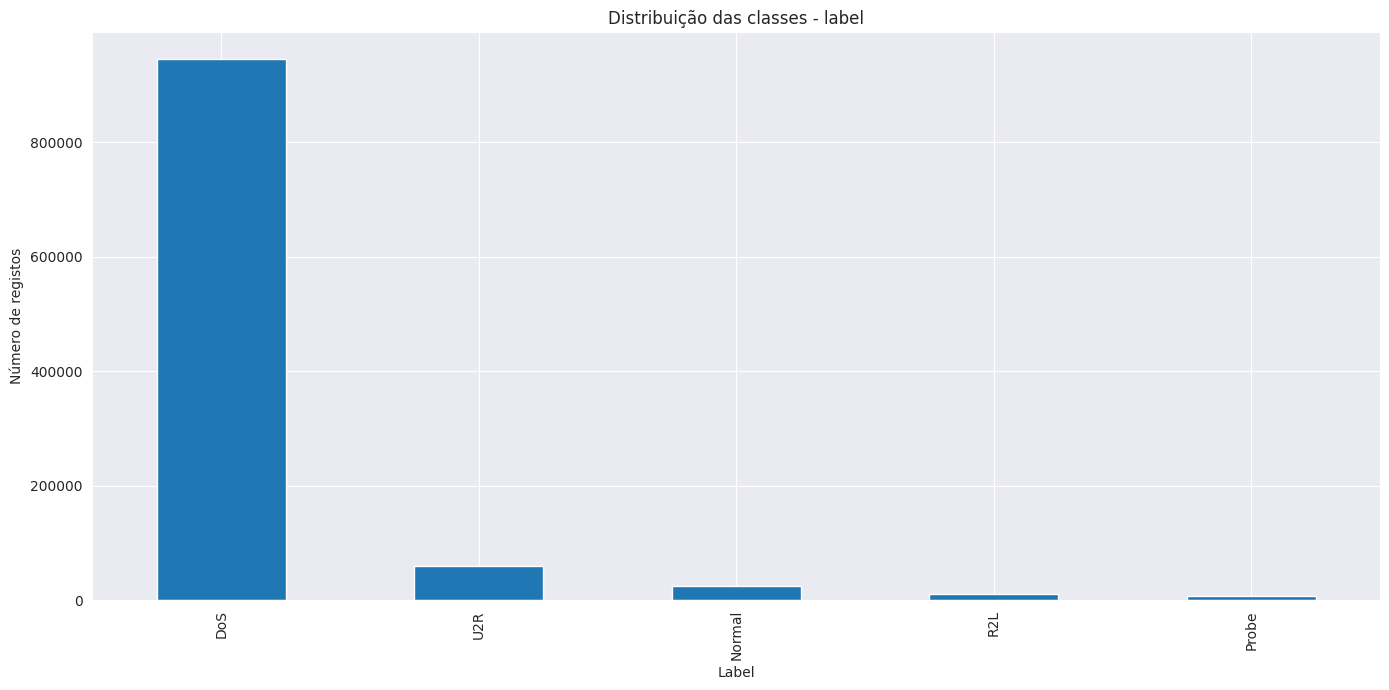

Número de classes: 5

Contagens:
label
DoS       945006
U2R        59233
Normal     24476
R2L        11915
Probe       7945
Name: count, dtype: int64


In [6]:
# 6.1 Contagem das classes
class_counts = df[TARGET].value_counts()

plt.figure(figsize=(14, 7))
class_counts.plot(kind="bar")
plt.title("Distribuição das classes - label")
plt.xlabel("Label")
plt.ylabel("Número de registos")
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

print("Número de classes:", df[TARGET].nunique())
print("\nContagens:")
print(class_counts)


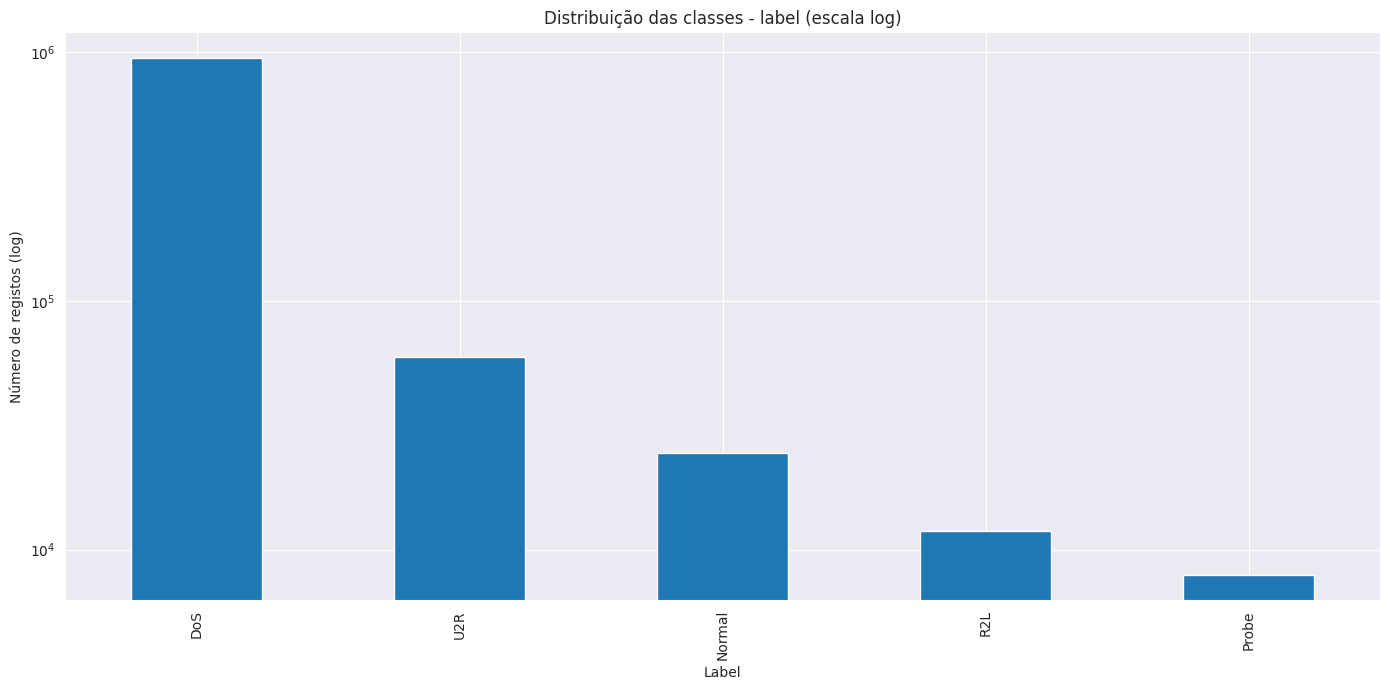

In [7]:
# 6.2 Distribuição em escala logarítmica
plt.figure(figsize=(14, 7))
class_counts.plot(kind="bar", logy=True)
plt.title("Distribuição das classes - label (escala log)")
plt.xlabel("Label")
plt.ylabel("Número de registos (log)")
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()


## 7. Estatísticas das variáveis numéricas

In [8]:
# Selecionar apenas variáveis numéricas
numeric_cols = df.select_dtypes(include=np.number).columns.tolist()

print("Número de variáveis numéricas:", len(numeric_cols))
display(df[numeric_cols].describe().T)


Número de variáveis numéricas: 46


,count,mean,std,min,25%,50%,75%,max
flow_duration,1048575.0,5.763553e+00,2.965660e+02,0.000000,0.000000e+00,0.000000e+00,1.042881e-01,9.943576e+04
Header_Length,1048575.0,7.759537e+04,4.664043e+05,0.000000,5.400000e+01,5.400000e+01,2.781200e+02,9.815555e+06
Protocol Type,1048575.0,9.062979e+00,8.936737e+00,0.000000,6.000000e+00,6.000000e+00,1.428000e+01,4.700000e+01
Duration,1048575.0,6.635523e+01,1.408680e+01,0.000000,6.400000e+01,6.400000e+01,6.400000e+01,2.550000e+02
Rate,1048575.0,9.146945e+03,9.974794e+04,0.000000,2.087155e+00,1.581371e+01,1.174380e+02,7.340032e+06
Srate,1048575.0,9.146945e+03,9.974794e+04,0.000000,2.087155e+00,1.581371e+01,1.174380e+02,7.340032e+06
Drate,1048575.0,1.807621e-06,8.501385e-04,0.000000,0.000000e+00,0.000000e+00,0.000000e+00,8.484654e-01
fin_flag_number,1048575.0,8.655842e-02,2.811870e-01,0.000000,0.000000e+00,0.000000e+00,0.000000e+00,1.000000e+00
syn_flag_number,1048575.0,2.073090e-01,4.053790e-01,0.000000,0.000000e+00,0.000000e+00,0.000000e+00,1.000000e+00
rst_flag_number,1048575.0,9.057149e-02,2.869989e-01,0.000000,0.000000e+00,0.000000e+00,0.000000e+00,1.000000e+00


In [9]:
# Skewness
skewness = df[numeric_cols].skew(numeric_only=True).sort_values(
    key=lambda x: x.abs(), ascending=False
)

print("Skewness das variáveis numéricas:")
display(skewness.to_frame("skewness"))


Skewness das variáveis numéricas:


,skewness
Drate,951.660260
DHCP,724.075963
flow_duration,172.391054
SSH,129.000369
ARP,122.379270
IPv,-93.854035
LLC,-93.854035
Covariance,90.596290
DNS,85.914796
urg_count,24.029876


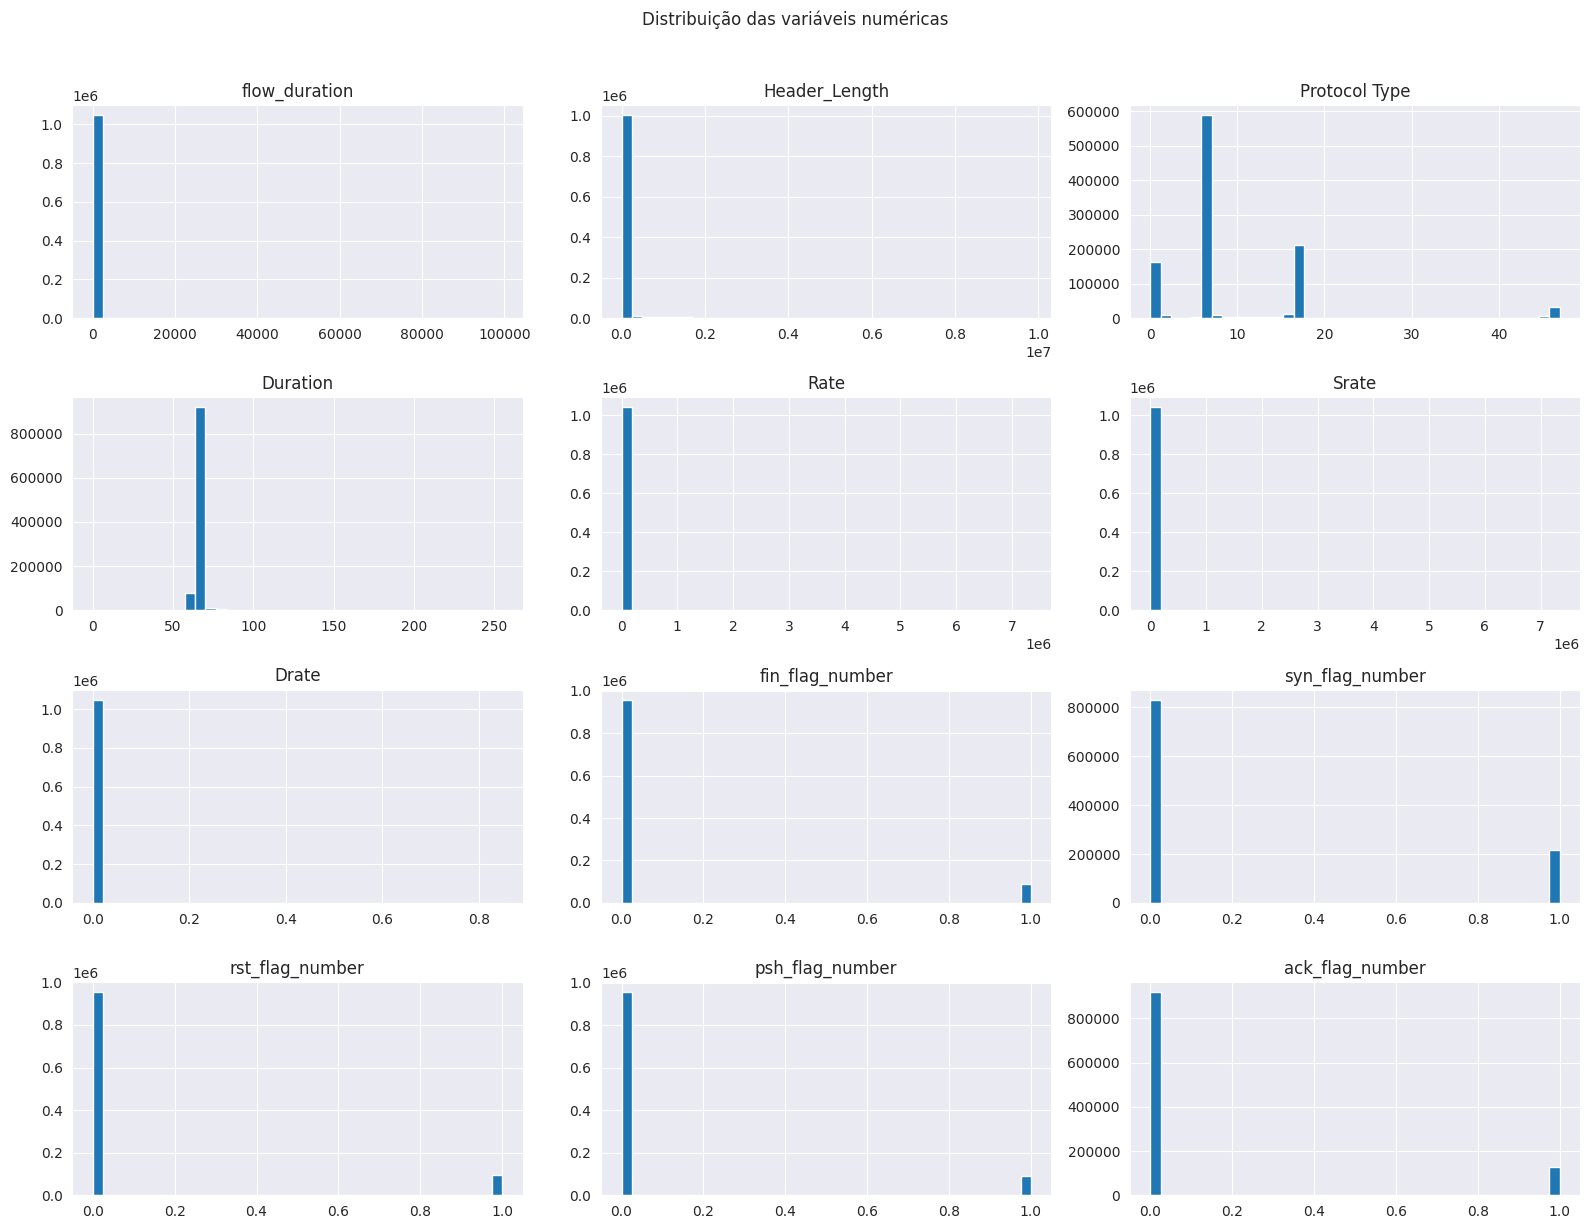

In [10]:
# Histogramas das principais variáveis numéricas
plot_cols = numeric_cols[:12]

df[plot_cols].hist(
    figsize=(16, 12),
    bins=40
)

plt.suptitle("Distribuição das variáveis numéricas", y=1.02)
plt.tight_layout()
plt.show()


## 8. Valores extremos / outliers

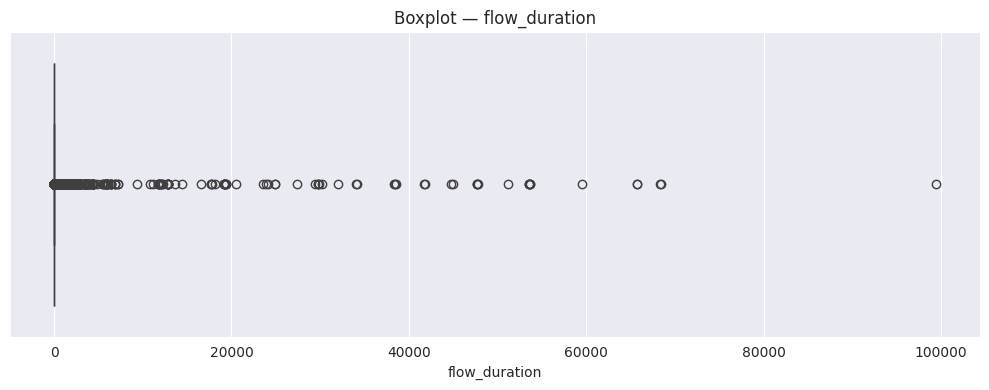

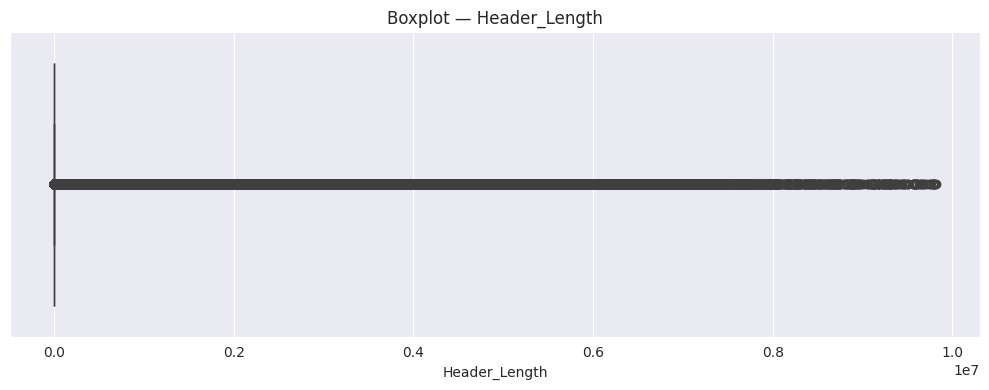

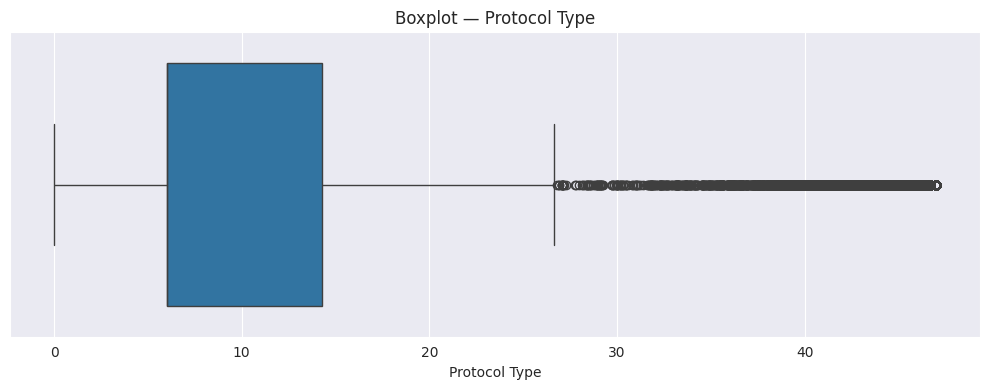

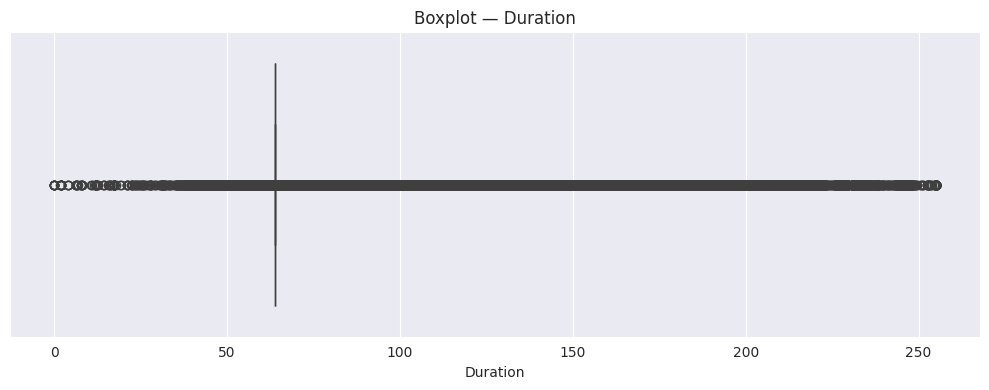

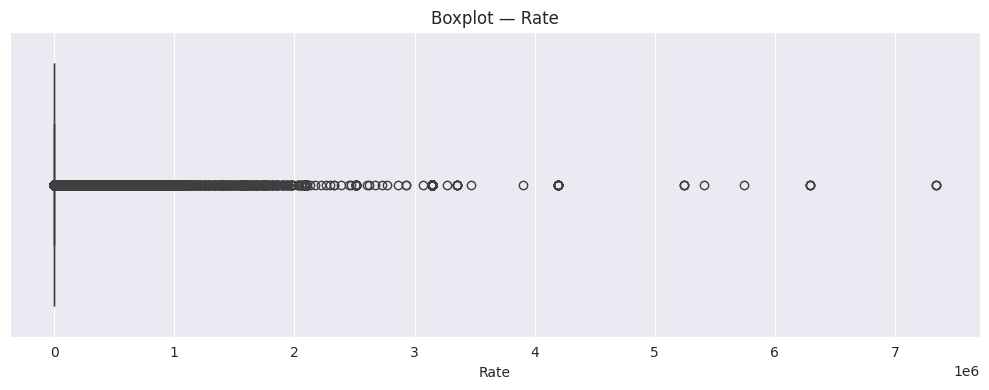

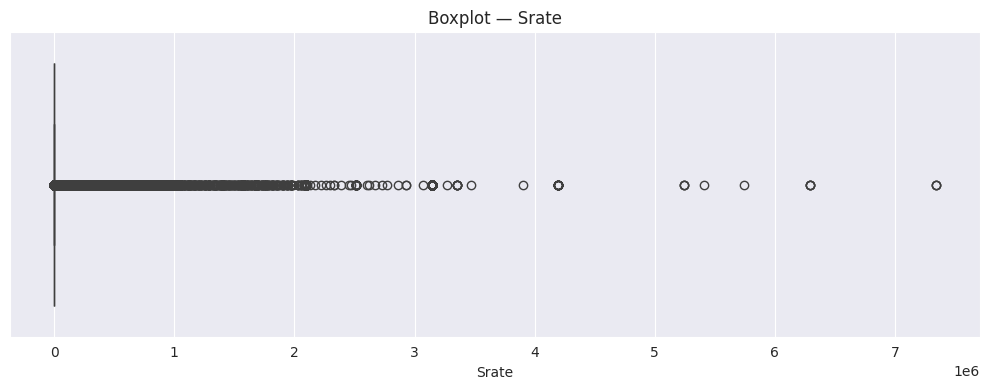

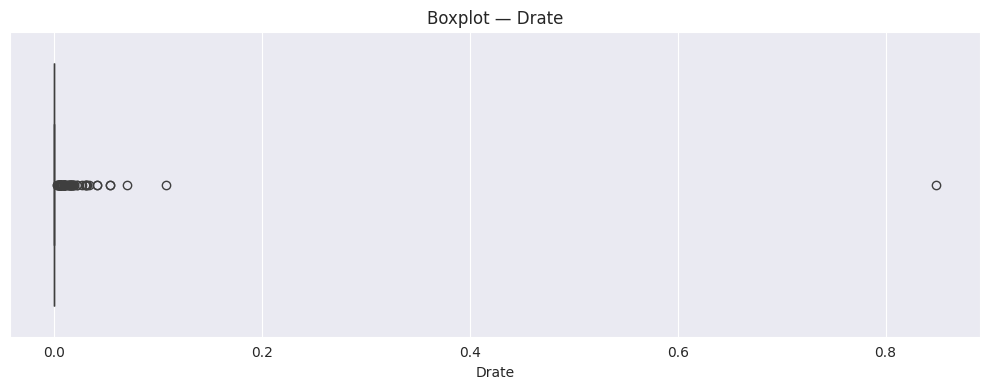

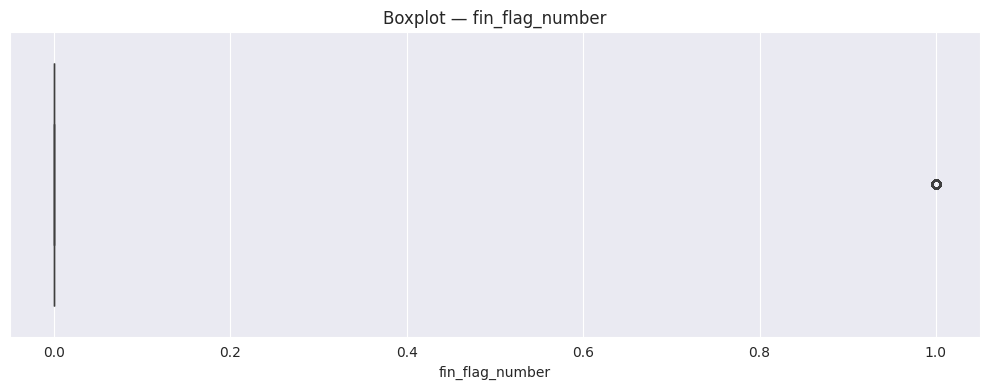

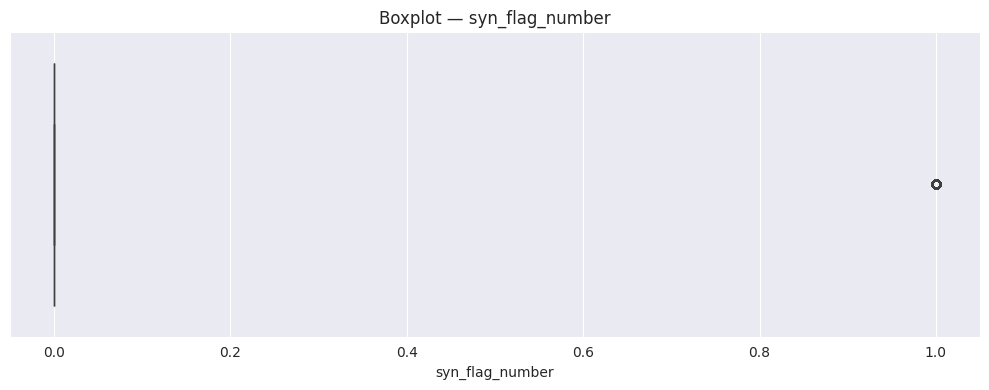

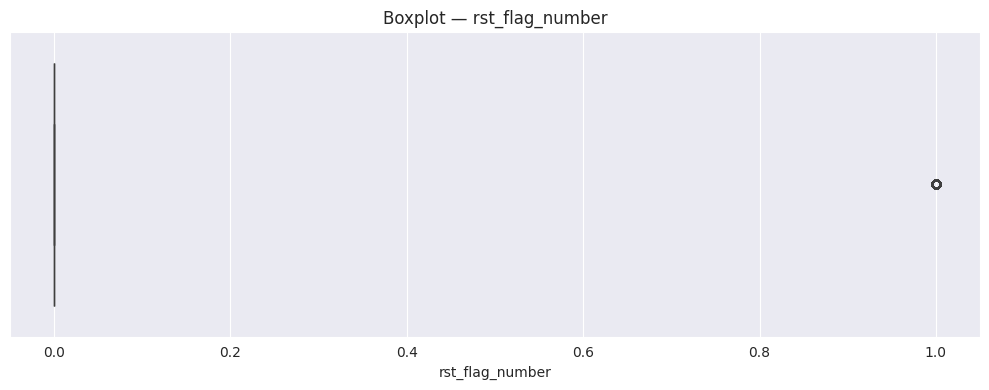

In [11]:
# Boxplots das primeiras variáveis numéricas
plot_cols = numeric_cols[:10]

for col in plot_cols:
    plt.figure(figsize=(10, 4))
    sns.boxplot(x=df[col])
    plt.title(f"Boxplot — {col}")
    plt.tight_layout()
    plt.show()


## 9. Correlação entre variáveis

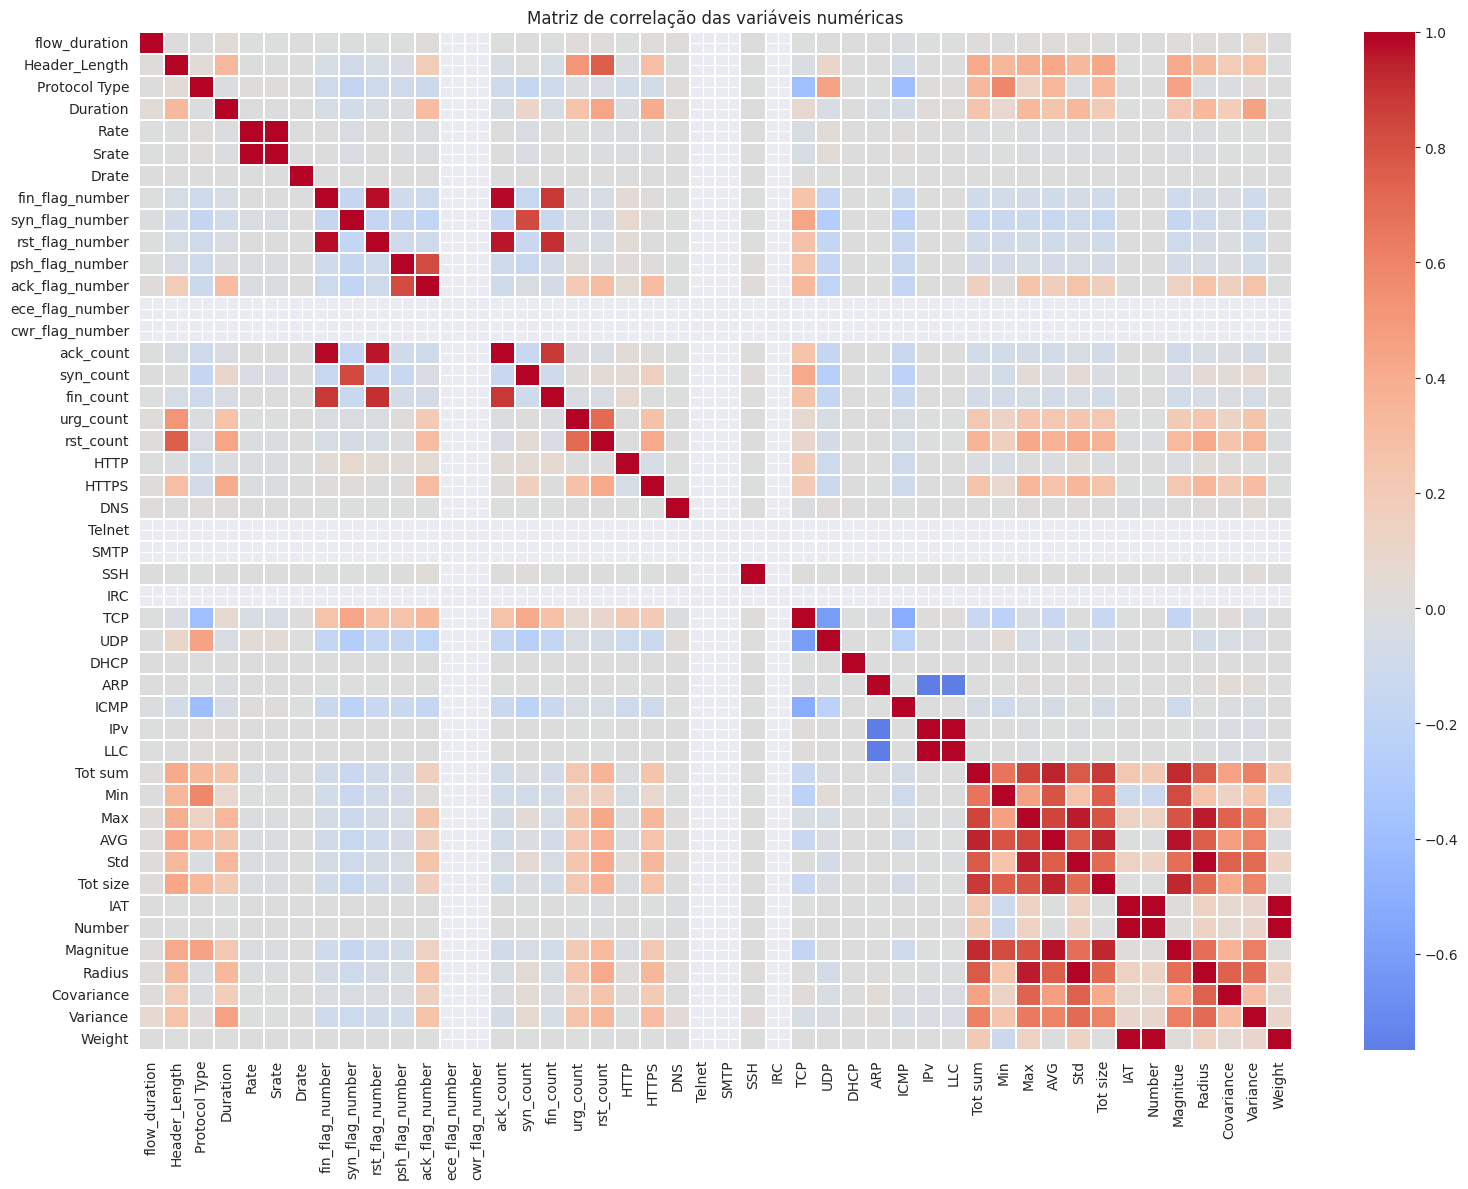

In [12]:
# Matriz de correlação
corr = df[numeric_cols].corr()

plt.figure(figsize=(16, 12))
sns.heatmap(
    corr,
    cmap="coolwarm",
    center=0,
    linewidths=0.2
)
plt.title("Matriz de correlação das variáveis numéricas")
plt.tight_layout()
plt.show()


In [13]:
# Pares de variáveis com correlação elevada
threshold = 0.80

upper = corr.where(
    np.triu(np.ones(corr.shape), k=1).astype(bool)
)

high_corr = (
    upper.stack()
    .sort_values(ascending=False)
)

high_corr = high_corr[
    high_corr.abs() >= threshold
]

print(f"Pares com |correlação| >= {threshold}:")
display(high_corr.to_frame("correlation"))


Pares com |correlação| >= 0.8:


correlation
IPv             LLC                 1.000000
Rate            Srate               1.000000
Std             Radius              0.999961
Number          Weight              0.999588
IAT             Weight              0.997308
                Number              0.996030
fin_flag_number ack_count           0.985947
                rst_flag_number     0.975055
AVG             Magnitue            0.967604
rst_flag_number ack_count           0.961549
Max             Std                 0.952807
                Radius              0.952778
AVG             Tot size            0.939981
Tot sum         AVG                 0.933092
Tot size        Magnitue            0.927557
Tot sum         Magnitue            0.923419
rst_flag_number fin_count           0.904653
Tot sum         Tot size            0.888671
ack_count       fin_count           0.887784
fin_flag_number fin_count           0.886464
Max             AVG                 0.845273
Tot sum         Max                 0.845085
syn_flag_number syn_count           0.828137
psh_flag_number ack_flag_number     0.826723
Min             Magnitue            0.825472

## 10. Relação entre features e classes

In [14]:
# Criar amostra estratificada para gráficos
MAX_PER_CLASS = 300

parts = []

for label, group in df.groupby(TARGET, observed=True):
    n = min(len(group), MAX_PER_CLASS)
    parts.append(group.sample(n=n, random_state=SEED))

amostra = pd.concat(parts, ignore_index=True)

print("Tamanho da amostra para gráficos:", amostra.shape)
print("Classes:", amostra[TARGET].nunique())


Tamanho da amostra para gráficos: (1500, 47)
Classes: 5


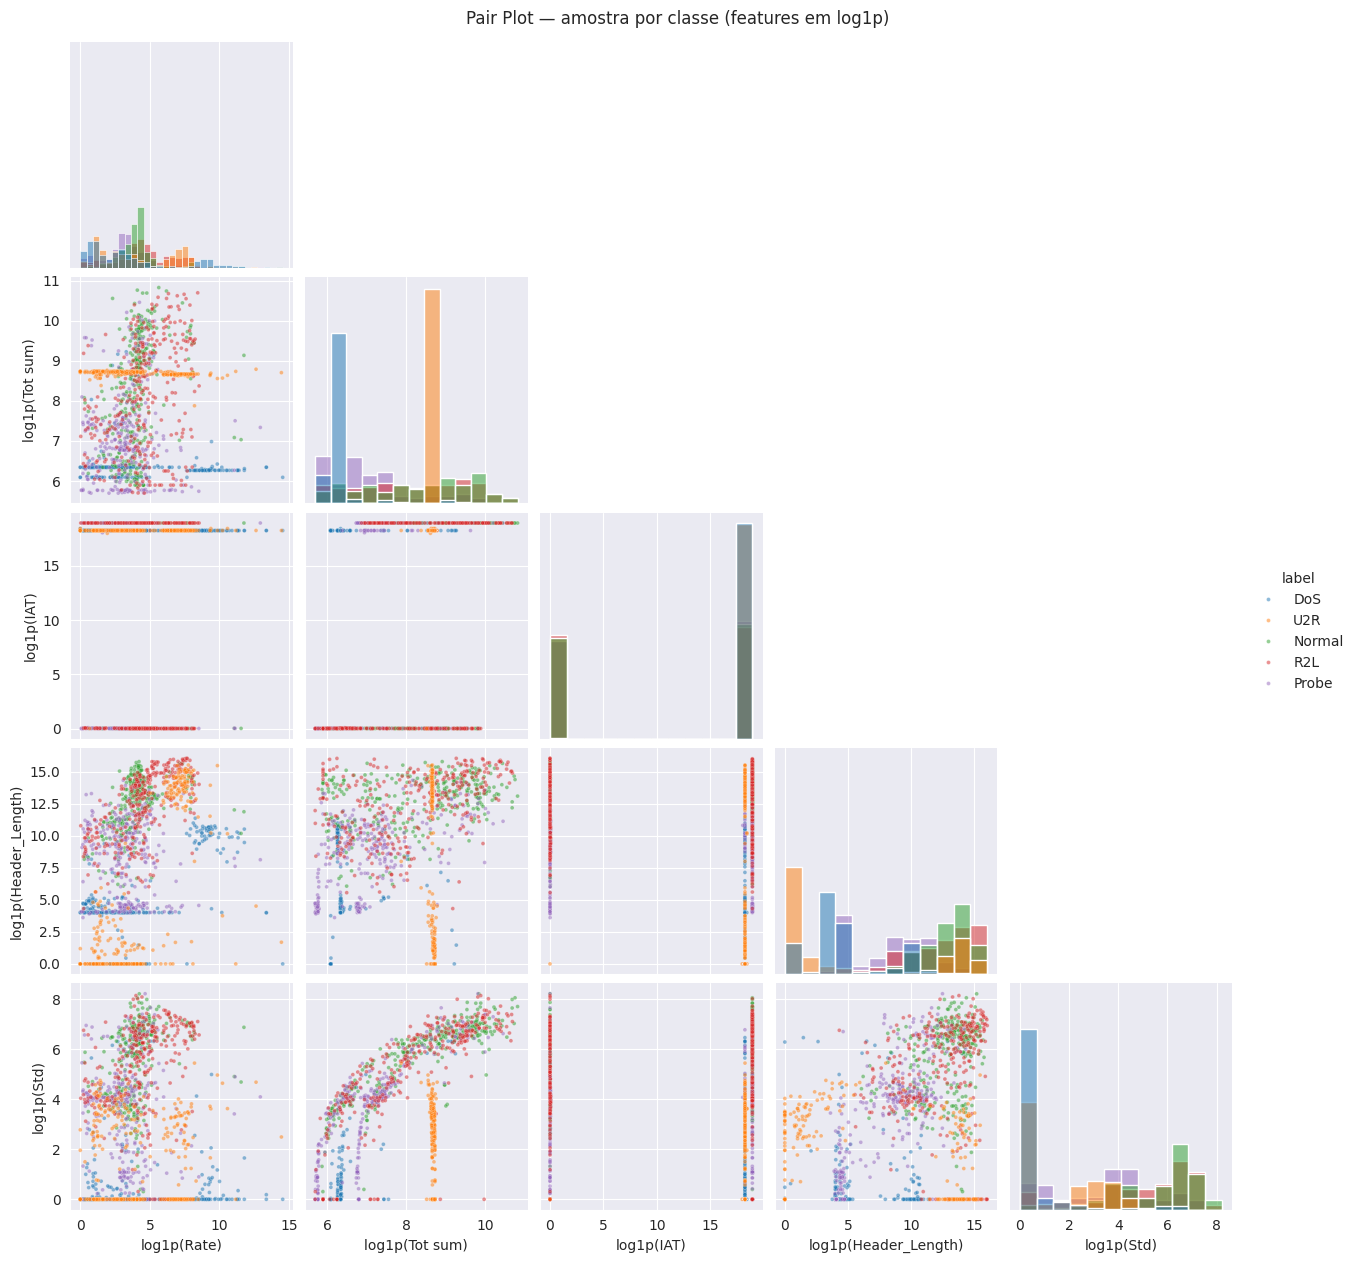

In [15]:
# Ordem das classes — definida ANTES de ser usada no pairplot
order = df[TARGET].value_counts().index.tolist()

# Pair plot apenas com algumas features disponíveis
preferred = [
    "Rate",
    "Tot sum",
    "IAT",
    "Header_Length",
    "Time_To_Live",
    "Std"
]

pair_features = [c for c in preferred if c in amostra.columns]

if len(pair_features) >= 2:
    pp = amostra[pair_features + [TARGET]].copy()

    # Aplicar log1p apenas a valores numéricos não negativos
    for c in pair_features:
        if (pp[c] >= 0).all():
            pp[f"log1p({c})"] = np.log1p(pp[c])

    log_features = [f"log1p({c})" for c in pair_features]

    g = sns.pairplot(
        pp[log_features + [TARGET]],
        hue=TARGET,
        hue_order=order,
        corner=True,
        plot_kws={"s": 8, "alpha": 0.5},
        diag_kind="hist"
    )

    g.fig.suptitle(
        "Pair Plot — amostra por classe (features em log1p)",
        y=1.01
    )

    plt.show()
else:
    print("Não existem pelo menos 2 das features esperadas para criar o pairplot.")


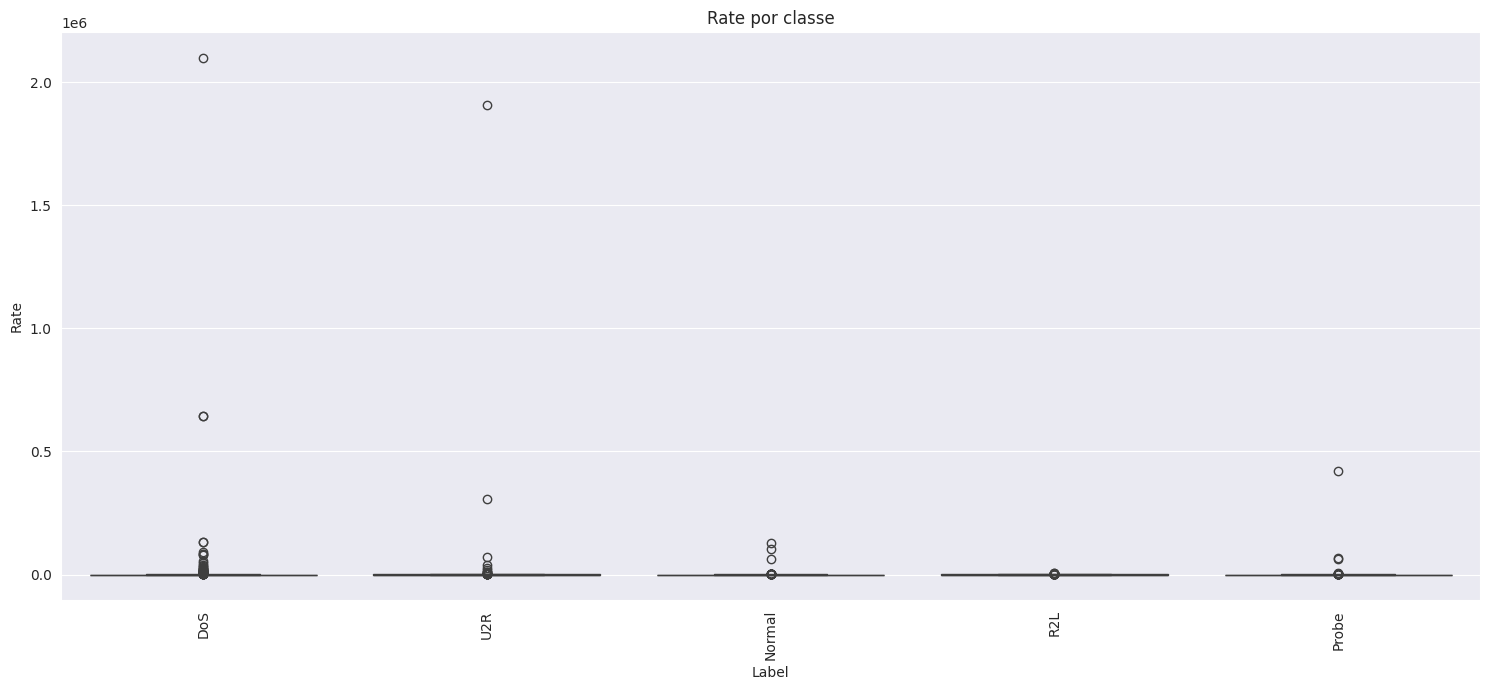

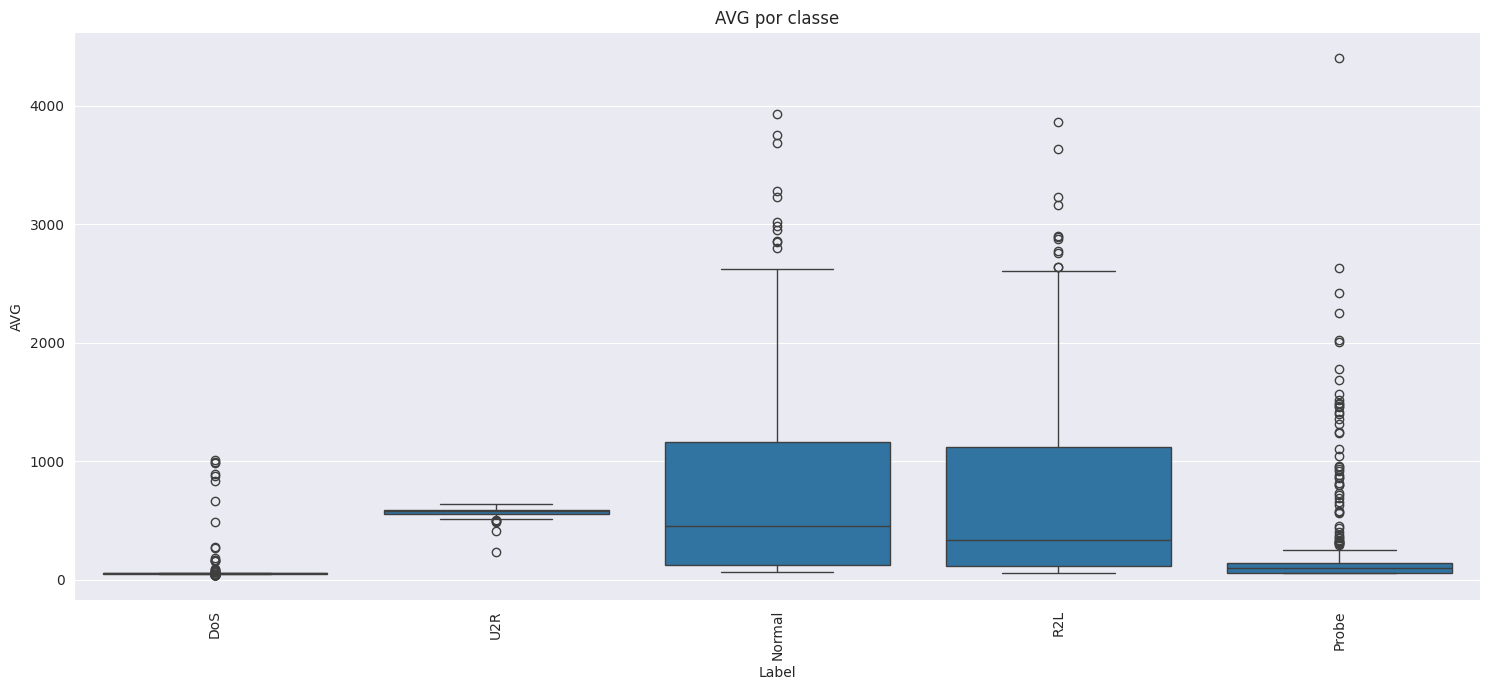

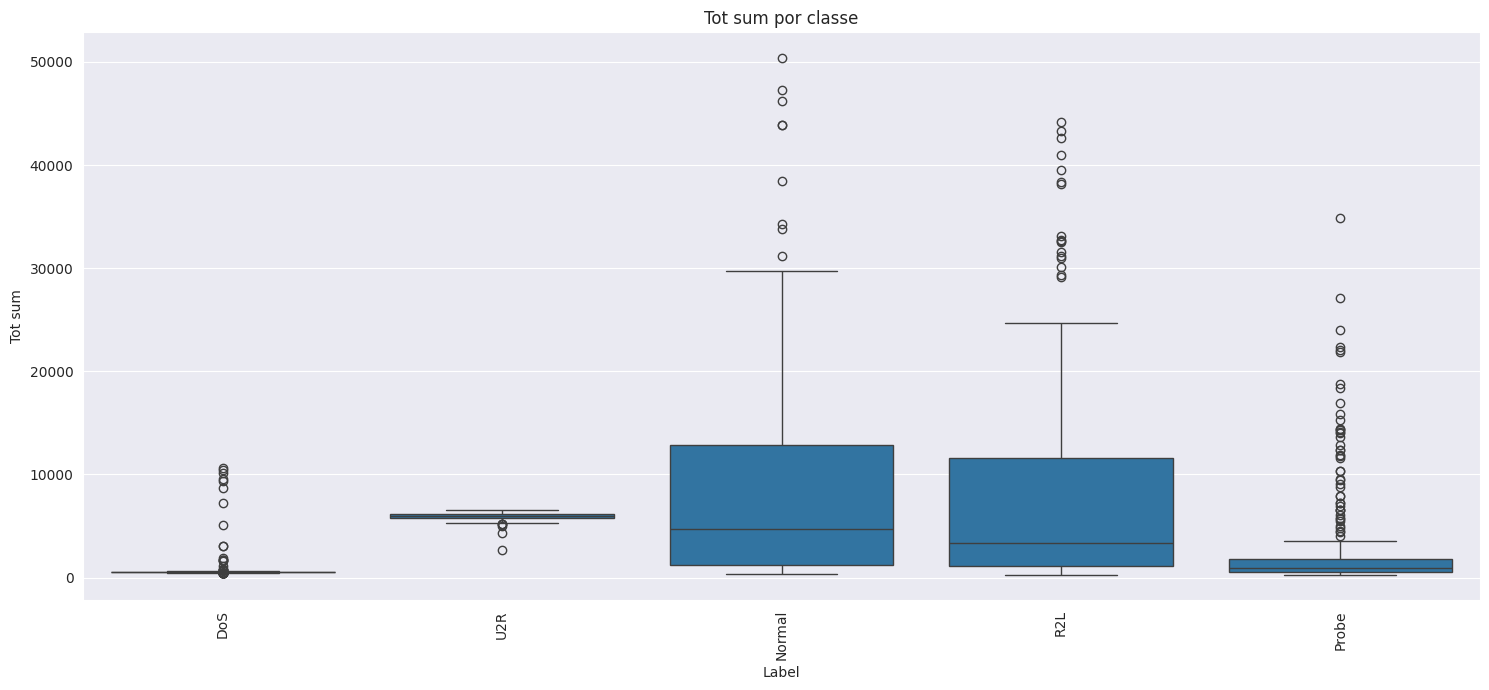

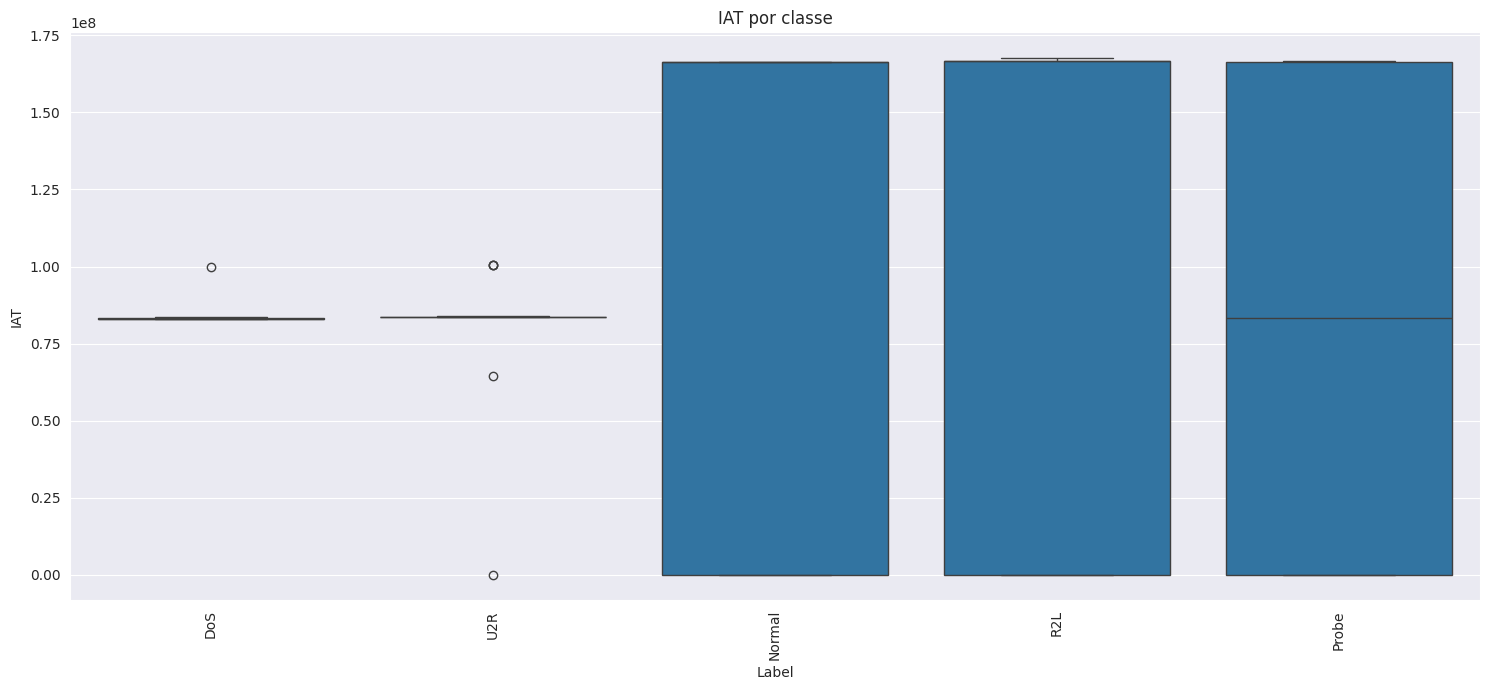

In [16]:
# Boxplots por classe para algumas features
features_by_class = [
    "Rate",
    "AVG",
    "Tot sum",
    "IAT"
]

available = [c for c in features_by_class if c in amostra.columns]

for col in available:
    plt.figure(figsize=(15, 7))
    sns.boxplot(
        data=amostra,
        x=TARGET,
        y=col,
        order=order
    )
    plt.title(f"{col} por classe")
    plt.xlabel("Label")
    plt.ylabel(col)
    plt.xticks(rotation=90)
    plt.tight_layout()
    plt.show()


## 11. Valores infinitos

In [17]:
# Verificar +inf e -inf
inf_counts = np.isinf(
    df[numeric_cols].to_numpy()
).sum()

print("Número total de valores infinitos:", int(inf_counts))

if inf_counts > 0:
    print("\nColunas com infinitos:")
    display(
        pd.Series(
            np.isinf(df[numeric_cols]).sum(),
            index=numeric_cols
        ).sort_values(ascending=False).to_frame("inf_count")
    )


Número total de valores infinitos: 0


## 12. Resumo para Data Preparation

In [18]:
# Resumo automático da EDA
print("========== RESUMO EDA ==========")
print("Número de linhas:", len(df))
print("Número de colunas:", df.shape[1])
print("Variável alvo:", TARGET)
print("Número de classes:", df[TARGET].nunique())
print("Valores nulos totais:", int(df.isnull().sum().sum()))
print("Duplicados:", int(df.duplicated().sum()))
print("Valores infinitos:", int(np.isinf(df[numeric_cols].to_numpy()).sum()))

print("\nClasses mais frequentes:")
display(df[TARGET].value_counts().head(10).to_frame("count"))

print("\nClasses menos frequentes:")
display(df[TARGET].value_counts().tail(10).to_frame("count"))

print("\nVariáveis com maior |skewness|:")
display(skewness.head(10).to_frame("skewness"))


========== RESUMO EDA ==========
Número de linhas: 1048575
Número de colunas: 47
Variável alvo: label
Número de classes: 5
Valores nulos totais: 0
Duplicados: 65556
Valores infinitos: 0

Classes mais frequentes:


,count
label,
DoS,945006
U2R,59233
Normal,24476
R2L,11915
Probe,7945



Classes menos frequentes:


,count
label,
DoS,945006
U2R,59233
Normal,24476
R2L,11915
Probe,7945



Variáveis com maior |skewness|:


,skewness
Drate,951.660260
DHCP,724.075963
flow_duration,172.391054
SSH,129.000369
ARP,122.379270
IPv,-93.854035
LLC,-93.854035
Covariance,90.596290
DNS,85.914796
urg_count,24.029876
